In [1]:
!pip -q install rdkit==2026.03.2

In [2]:
from typing import List, Tuple, Dict, Optional
from collections import Counter, defaultdict
from itertools import product, chain

import numpy as np
import pandas as pd
import math

from rdkit import Chem
from rdkit.Chem import AllChem, DataStructs, Descriptors, rdMolDescriptors, rdFingerprintGenerator, Draw , Lipinski
from rdkit.Chem.Scaffolds import MurckoScaffold
from rdkit.Chem.MolStandardize import rdMolStandardize
from rdkit.DataStructs.cDataStructs import BulkTanimotoSimilarity

import matplotlib.pyplot as plt

In [3]:
# Path to dataset
meta_data_csv = "compound_metadata.csv"
multilabel_data_csv = "bioactivities_multilabel.csv"

In [4]:
meta_data_df = pd.read_csv(meta_data_csv)
meta_data_df.columns

Index(['compound_id', 'InChIKey', 'NP_name', 'PubChem_ID', 'Source_species',
       'SMILES', 'canonical_smiles', 'Reference', 'source_database',
       'NP_pathway'],
      dtype='object')

In [5]:
multilabel_data_df = pd.read_csv(multilabel_data_csv)
multilabel_data_df.columns

Index(['compound_id', 'Agrochemical', 'Anti-aging', 'Anti-inflammatory',
       'Antiallergic', 'Antibacterial', 'Anticancer', 'Antifungal',
       'Antimicrobial', 'Antioxidant', 'Antiparasitic', 'Antiviral',
       'Cardiovascular', 'Cytotoxic', 'Enzyme/Target Inhibition',
       'Immunomodulatory', 'Metabolic', 'Neurological', 'Toxic'],
      dtype='object')

In [23]:
# Multi-label bioactivity columns
Bio_cols = ['Agrochemical', 'Anti-aging', 'Anti-inflammatory',
       'Antiallergic', 'Antibacterial', 'Anticancer', 'Antifungal',
       'Antimicrobial', 'Antioxidant', 'Antiparasitic', 'Antiviral',
       'Cardiovascular', 'Cytotoxic', 'Enzyme/Target Inhibition',
       'Immunomodulatory', 'Metabolic', 'Neurological', 'Toxic']

# Single-class NP class column
NP_pathway_col = 'NP_pathway'
np_pathway_names = meta_data_df["NP_pathway"].unique()
print(np_pathway_names)

['Polyketides' 'Unknown' 'Alkaloids' 'Shikimates and Phenylpropanoids'
 'Terpenoids' 'Amino acids and Peptides' 'Fatty acids' 'Carbohydrates']


In [7]:
# RDKit SMILES standardization

def standardize_smiles(smiles: str):

  if smiles is None:
    return None

  mol = Chem.MolFromSmiles(smiles)
  mol = rdMolStandardize.Cleanup(mol) #  Normalize the molecule
  mol = rdMolStandardize.FragmentParent(mol) # Removing fragments
  uncharger = rdMolStandardize.Uncharger()  # Neutralizing
  mol = uncharger.uncharge(mol)

  return Chem.MolToSmiles(mol,canonical=True, isomericSmiles=True)

def apply_smiles_standardization(df: pd.DataFrame,
    smiles_col: str, out_col: str):
  df = df.copy()
  df[out_col] = df[smiles_col].apply(standardize_smiles)

  return df

In [8]:
# Fingerprints (ECFP4 = radius 2, 2048 bits)

def smiles_to_ecfp(smiles: List[str], radius=2, nbits=2048):
    fpgen = rdFingerprintGenerator.GetMorganGenerator(radius=radius, fpSize=nbits)
    fps = []
    for i, smi in enumerate(smiles):
        m = Chem.MolFromSmiles(smi)
        if m is None: continue
        fp=fpgen.GetFingerprint(m)
        fps.append(fp)

    return fps

In [9]:
# Molecules standardize
meta_data_df = apply_smiles_standardization(meta_data_df, smiles_col="canonical_smiles", out_col="smiles_std")

Streaming output truncated to the last 5000 lines.
[15:47:16] Initializing MetalDisconnector
[15:47:16] Running MetalDisconnector
[15:47:16] Initializing Normalizer
[15:47:16] Running Normalizer
[15:47:16] Initializing MetalDisconnector
[15:47:16] Running MetalDisconnector
[15:47:16] Initializing Normalizer
[15:47:16] Running Normalizer
[15:47:16] Running LargestFragmentChooser
[15:47:16] Running Uncharger
[15:47:16] Initializing MetalDisconnector
[15:47:16] Running MetalDisconnector
[15:47:16] Initializing Normalizer
[15:47:16] Running Normalizer
[15:47:16] Initializing MetalDisconnector
[15:47:16] Running MetalDisconnector
[15:47:16] Initializing Normalizer
[15:47:16] Running Normalizer
[15:47:16] Running LargestFragmentChooser
[15:47:16] Running Uncharger
[15:47:16] Initializing MetalDisconnector
[15:47:16] Running MetalDisconnector
[15:47:16] Initializing Normalizer
[15:47:16] Running Normalizer
[15:47:16] Initializing MetalDisconnector
[15:47:16] Running MetalDisconnector
[15:47:1

In [10]:
# Generate ECFP fingerprint
fps = smiles_to_ecfp(meta_data_df["smiles_std"])

In [11]:
# Chemical similarity analysis
similarities = []
for i in range(len(fps)):
    sims = BulkTanimotoSimilarity(fps[i],fps[i+1:])
    similarities.extend(sims)

similarities = np.array(similarities)

min_sim = similarities.min()
max_sim = similarities.max()
median_sim = np.median(similarities)

print("Min similarity:",min_sim)
print("Max similarity:",max_sim)
print("Median similarity:",median_sim)



Min similarity: 0.0
Max similarity: 1.0
Median similarity: 0.1134020618556701


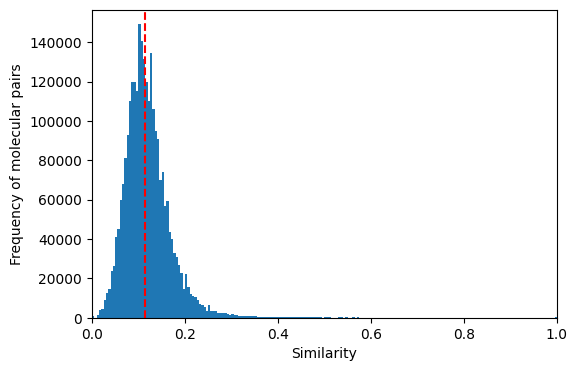

In [12]:
# Histogram of similarities
plt.figure(figsize=(6,4))
plt.hist(similarities, bins=200)
plt.axvline(median_sim, color="red",    ls="--", label=f"Median={median_sim:.3f}")
plt.xlabel("Similarity")
plt.ylabel("Frequency of molecular pairs")
plt.xlim(0,1)
plt.savefig("Similarity_fig.png", dpi=300, bbox_inches="tight")
plt.savefig("Similarity_fig.pdf", bbox_inches='tight',pad_inches=0.05)
plt.show()

In [13]:
def get_scaffold(smiles):
    try:
        mol = Chem.MolFromSmiles(smiles)
        if mol is None:
            return None

        Chem.RemoveStereochemistry(mol)

        scaffold = MurckoScaffold.GetScaffoldForMol(mol)
        if scaffold is None or scaffold.GetNumAtoms() == 0:
            return None

        return Chem.MolToSmiles(scaffold, canonical=True, isomericSmiles=True)

    except Exception:
        return None

In [14]:
# SMILES report

n_compounds=len(meta_data_df)
print(f"Total molecules: {n_compounds}")

# uniqueness
uniq = meta_data_df["smiles_std"].nunique()
print(f"Unique SMILES: {uniq}")

# Scaffold check
meta_data_df["scaffold"] = meta_data_df["smiles_std"].apply(get_scaffold)

print("Scaffolds analysis:")
n_scaffolds = meta_data_df["scaffold"].nunique()
print(f"Unique scaffolds: {n_scaffolds}")
scaffold_percent = (n_scaffolds / n_compounds) * 100
print(f"Scaffolds percentage (%): {scaffold_percent}")

n_single_scaffolds = len(
        meta_data_df.groupby("scaffold").filter(lambda x: len(x) == 1))
print(f"Number of singleton scaffolds: {n_single_scaffolds}")

singleton_percent = (n_single_scaffolds / n_scaffolds) * 100
print(f"Singleton percentage (%): {singleton_percent}")

n_no_scaffold_mols = (meta_data_df["scaffold"].isna()).sum()
print(f"Number of molecules with no scaffold: {n_no_scaffold_mols}")

n_multi_frag_mols = meta_data_df["smiles_std"].str.contains(r"\.").sum()
n_no_ring_mols = n_no_scaffold_mols - n_multi_frag_mols
print(f"Multi-fragment molecules: {n_multi_frag_mols}")
print(f"Number of molecules with no ring systems: {n_no_ring_mols}")

scaffold_counts = meta_data_df["scaffold"].value_counts()
print(scaffold_counts.describe())




Total molecules: 2304
Unique SMILES: 2303
Scaffolds analysis:
Unique scaffolds: 985
Scaffolds percentage (%): 42.75173611111111
Number of singleton scaffolds: 641
Singleton percentage (%): 65.0761421319797
Number of molecules with no scaffold: 68
Multi-fragment molecules: 0
Number of molecules with no ring systems: 68
count    985.000000
mean       2.270051
std        5.268036
min        1.000000
25%        1.000000
50%        1.000000
75%        2.000000
max      130.000000
Name: count, dtype: float64


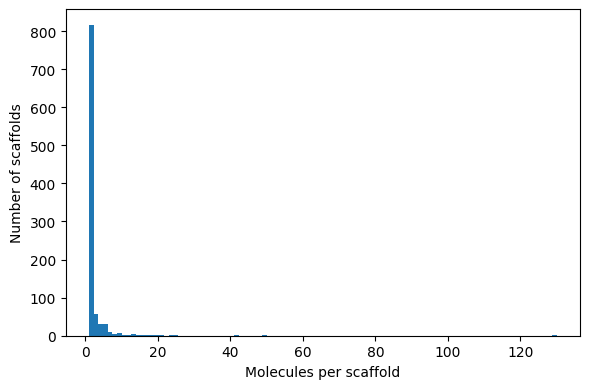

In [15]:
# Plot scaffold frequency distribution

scaffold_counts = meta_data_df["scaffold"].value_counts()

plt.figure(figsize=(6,4))
plt.hist(scaffold_counts, bins=100)
plt.xlabel("Molecules per scaffold")
plt.ylabel("Number of scaffolds")

plt.tight_layout()

plt.savefig("scaffold_distribution_fig.png", dpi=300, bbox_inches="tight")
plt.savefig("scaffold_distribution_fig.pdf", bbox_inches='tight',pad_inches=0.05)
plt.show()

In [16]:
# Draw the top five scaffolds

scaffold_series = meta_data_df["scaffold"].replace("",None).dropna()
scaffold_count = scaffold_series.value_counts()
total_scaffold_occ = scaffold_count.sum()

scaffold_percent = scaffold_count / total_scaffold_occ * 100

top5 = scaffold_count.head(5)
mols = [Chem.MolFromSmiles(s) for s in top5.index]
legends = [f"{scaffold_percent[i]:.2f}%" for i in top5.index]
img = Draw.MolsToGridImage (mols,molsPerRow=5, legends=legends, returnPNG=False)
img.save("top_scaffold.png")
img.save("top_scaffold.pdf")


In [17]:
# Calculate physicochemical properties (MW, LogP, HBA, HBD, TPSA, RotBonds)
def cala_properties (simles):

  mol = Chem.MolFromSmiles(simles)

  if mol is None:
    return None, None, None, None, None, None

  mw = Descriptors.MolWt(mol)
  logp = Descriptors.MolLogP(mol)
  hba = rdMolDescriptors.CalcNumHBA(mol)
  hbd = rdMolDescriptors.CalcNumHBD(mol)
  TPSA = rdMolDescriptors.CalcTPSA(mol)
  RotBonds = rdMolDescriptors.CalcNumRotatableBonds(mol)

  return mw, logp, hba, hbd, TPSA, RotBonds

In [18]:
meta_data_df[["MW", "LogP", "HBA", "HBD", "TPSA", "RotBonds"]] = meta_data_df["smiles_std"].apply(
    lambda x: cala_properties(x)).apply(pd.Series)

In [19]:
# Print Lipinski and Veber rules results

mw_pass= (meta_data_df["MW"] <= 500).sum()
logp_pass = (meta_data_df["LogP"] <= 5).sum()
hba_pass = (meta_data_df["HBA"] <= 10).sum()
hbd_pass = (meta_data_df["HBD"] <= 5).sum()
TPSA_pass = (meta_data_df["TPSA"] <= 140).sum()
RotBonds_pass = (meta_data_df["RotBonds"] <= 10).sum()

complete_lipinski_pass = (
    (meta_data_df["MW"] <= 500) &
    (meta_data_df["LogP"] <= 5) &
    (meta_data_df["HBA"] <= 10) &
    (meta_data_df["HBD"] <= 5)
).sum()

print("Lipinski compliant compounds:", complete_lipinski_pass.sum())

complete_veber_pass = (
    (meta_data_df["TPSA"] <= 140) &
    (meta_data_df["RotBonds"] <= 10)
).sum()

print("Veber compliant compounds:", complete_veber_pass.sum())

Lipinski compliant compounds: 1854
Veber compliant compounds: 2080


In [20]:
# Print detailed Lipinski and Veber rules results
total = len (meta_data_df)
Lipinski_table = pd.DataFrame({
    "Feature":[
        "Molecular weight",
        "LogP",
        "H-bond acceptors",
        "H-bond donors",
        "Complete Lipinski rules"
    ],
    "Number of compounds fulfilling the rule":[
        mw_pass,
        logp_pass,
        hba_pass,
        hbd_pass,
        complete_lipinski_pass
    ],
    "Percentage of Database fulfilling the rule":[
        mw_pass/total*100,
        logp_pass/total*100,
        hba_pass/total*100,
        hbd_pass/total*100,
        complete_lipinski_pass/total*100
    ]
})
Lipinski_table.to_csv("Lipinski_rule.csv",index=False)
print(Lipinski_table)

Veber_table = pd.DataFrame({
    "Feature":[
        "Topological Polar Surface Area",
        "Rotatable Bonds",
        "Complete Veber rules"
    ],
    "Number of compounds fulfilling the rule":[
        TPSA_pass,
        RotBonds_pass,
        complete_veber_pass
    ],
    "Percentage of Database fulfilling the rule":[
        TPSA_pass/total*100,
        RotBonds_pass/total*100,
        complete_veber_pass/total*100,
    ]
})
Veber_table.to_csv("Veber_rule.csv",index=False)
print(Veber_table)

                   Feature  Number of compounds fulfilling the rule  \
0         Molecular weight                                     2021   
1                     LogP                                     2075   
2         H-bond acceptors                                     2217   
3            H-bond donors                                     2243   
4  Complete Lipinski rules                                     1854   

   Percentage of Database fulfilling the rule  
0                                   87.717014  
1                                   90.060764  
2                                   96.223958  
3                                   97.352431  
4                                   80.468750  
                          Feature  Number of compounds fulfilling the rule  \
0  Topological Polar Surface Area                                     2119   
1                 Rotatable Bonds                                     2230   
2            Complete Veber rules                  

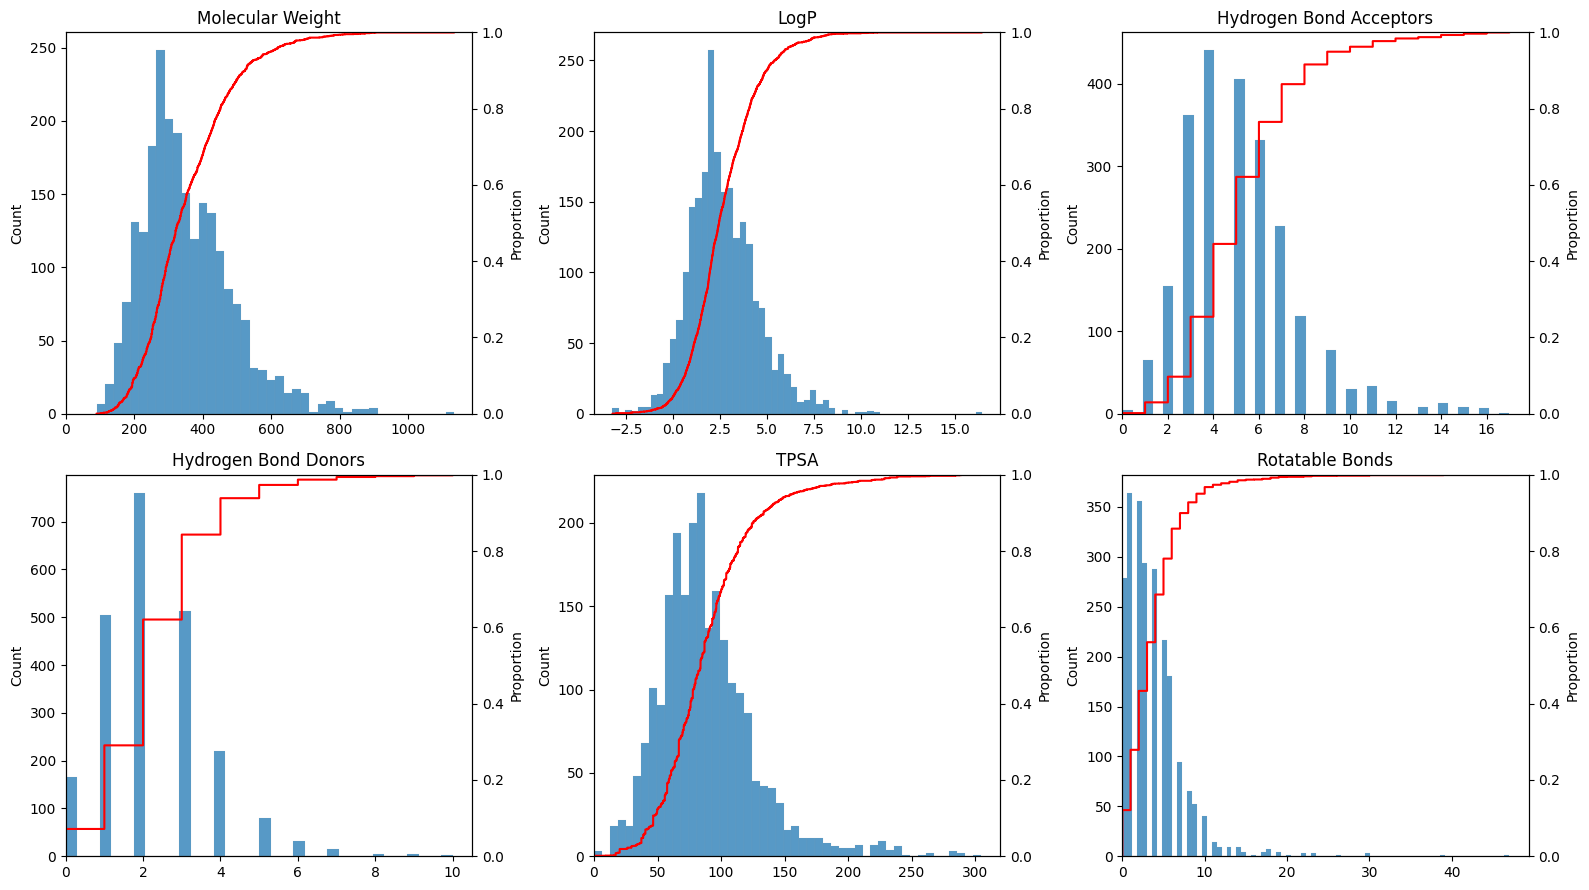

In [21]:
import seaborn as sns

descriptor_cols = ["MW", "LogP", "HBA", "HBD", "TPSA", "RotBonds"]

titles = {
        "MW": "Molecular Weight",
        "LogP": "LogP",
        "HBA": "Hydrogen Bond Acceptors",
        "HBD": "Hydrogen Bond Donors",
        "TPSA": "TPSA",
        "RotBonds": "Rotatable Bonds"
    }

fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(16, 9))
axes = axes.flatten()

for i, col in enumerate(descriptor_cols):
  # Histogram
    sns.histplot(
        data=meta_data_df,
        x=col,
        ax=axes[i],
        edgecolor="darkgray",
        linewidth=0.05
    )

    # Secondary axis for cumulative proportion
    ax2 = axes[i].twinx()

    sns.ecdfplot(
        data=meta_data_df,
        x=col,
        ax=ax2,
        color="red",
        linewidth=1.5
    )

    axes[i].set_title(titles[col])
    axes[i].set_xlabel("")
    axes[i].set_ylabel("Count")

    ax2.set_ylabel("Proportion")
    ax2.set_ylim(0, 1)

    axes[i].set_title(titles[col])
    axes[i].set_xlabel("")
    axes[i].set_ylabel("Count")

    if col in ["MW", "TPSA", "HBA", "HBD", "RotBonds"]:
        axes[i].set_xlim(left=0)

plt.tight_layout()
plt.savefig("descriptor_distributions.png",dpi=300,bbox_inches="tight")
plt.savefig("descriptor_distributions.pdf", bbox_inches='tight',pad_inches=0.05)
plt.show()

In [24]:
# Count compounds in each bioactivity

print("\nCount bioactivities:\n")
for col in Bio_cols:
    print(f"{col} -> {int(multilabel_data_df[col].sum())} compounds")


Count bioactivities:

Agrochemical -> 135 compounds
Anti-aging -> 2 compounds
Anti-inflammatory -> 229 compounds
Antiallergic -> 3 compounds
Antibacterial -> 771 compounds
Anticancer -> 43 compounds
Antifungal -> 531 compounds
Antimicrobial -> 1145 compounds
Antioxidant -> 147 compounds
Antiparasitic -> 110 compounds
Antiviral -> 105 compounds
Cardiovascular -> 15 compounds
Cytotoxic -> 794 compounds
Enzyme/Target Inhibition -> 92 compounds
Immunomodulatory -> 58 compounds
Metabolic -> 194 compounds
Neurological -> 109 compounds
Toxic -> 10 compounds


In [25]:
# Count compounds in each NP pathway
NP_class_counts = meta_data_df["NP_pathway"].value_counts()
for cls, n in NP_class_counts.items():
    print(f"{cls}: {n}")

Unknown: 814
Polyketides: 696
Terpenoids: 244
Alkaloids: 235
Shikimates and Phenylpropanoids: 221
Amino acids and Peptides: 58
Fatty acids: 32
Carbohydrates: 4


Bioactivity percentage:
 Antimicrobial               49.696181
Cytotoxic                   34.461806
Antibacterial               33.463542
Antifungal                  23.046875
Anti-inflammatory            9.939236
Metabolic                    8.420139
Antioxidant                  6.380208
Agrochemical                 5.859375
Antiparasitic                4.774306
Neurological                 4.730903
Antiviral                    4.557292
Enzyme/Target Inhibition     3.993056
Immunomodulatory             2.517361
Anticancer                   1.866319
Cardiovascular               0.651042
Toxic                        0.434028
Antiallergic                 0.130208
Anti-aging                   0.086806
dtype: float64


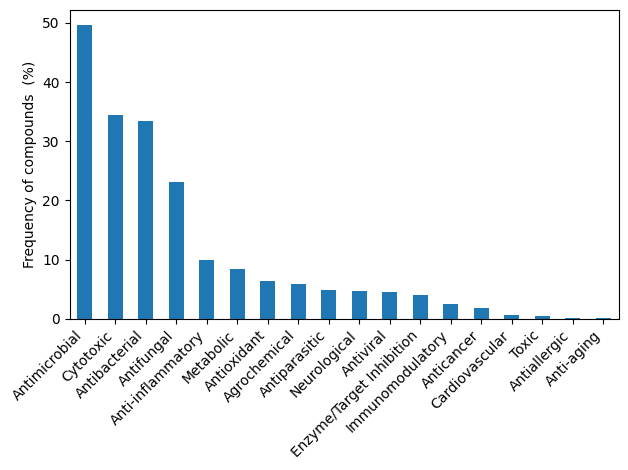

In [26]:
# Bioactivity distribution
bio_counts = multilabel_data_df[Bio_cols].fillna(0).astype(int).sum().sort_values(ascending=False)

total_comp = len(multilabel_data_df)
bio_percent = (bio_counts/total_comp) * 100
print("Bioactivity percentage:\n",bio_percent)

plt.figure()
bio_percent.plot(kind="bar")
plt.ylabel("Frequency of compounds  (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("Bioactivity_distribution_fig.png", dpi=300, bbox_inches="tight")
plt.savefig("Bioactivity_distribution_fig.pdf", bbox_inches='tight',pad_inches=0.05)
plt.show()

Biosynthetic pathway percentage:
 NP_pathway
Unknown                            35.329861
Polyketides                        30.208333
Terpenoids                         10.590278
Alkaloids                          10.199653
Shikimates and Phenylpropanoids     9.592014
Amino acids and Peptides            2.517361
Fatty acids                         1.388889
Carbohydrates                       0.173611
Name: count, dtype: float64


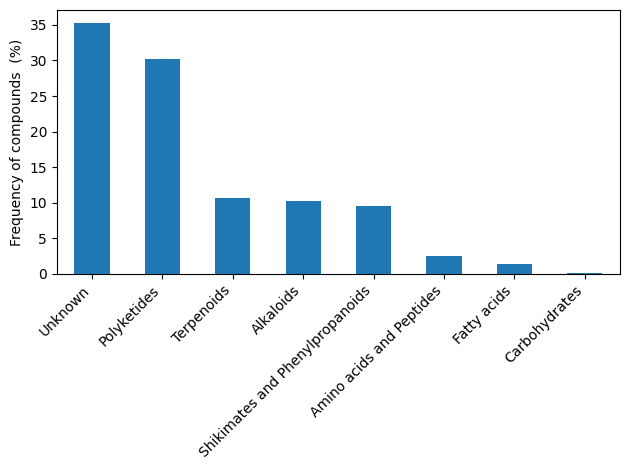

In [27]:
# Class distribution
class_counts = meta_data_df[NP_pathway_col].value_counts()

total_comp = len(meta_data_df)
class_percent = (class_counts/total_comp) * 100
print("Biosynthetic pathway percentage:\n",class_percent)

plt.figure()
class_percent.plot(kind="bar")
plt.xlabel("")
plt.ylabel("Frequency of compounds  (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("Class_distribution_fig.png", dpi=300, bbox_inches="tight")
plt.savefig("Class_distribution_fig.pdf", bbox_inches='tight',pad_inches=0.05)
plt.show()

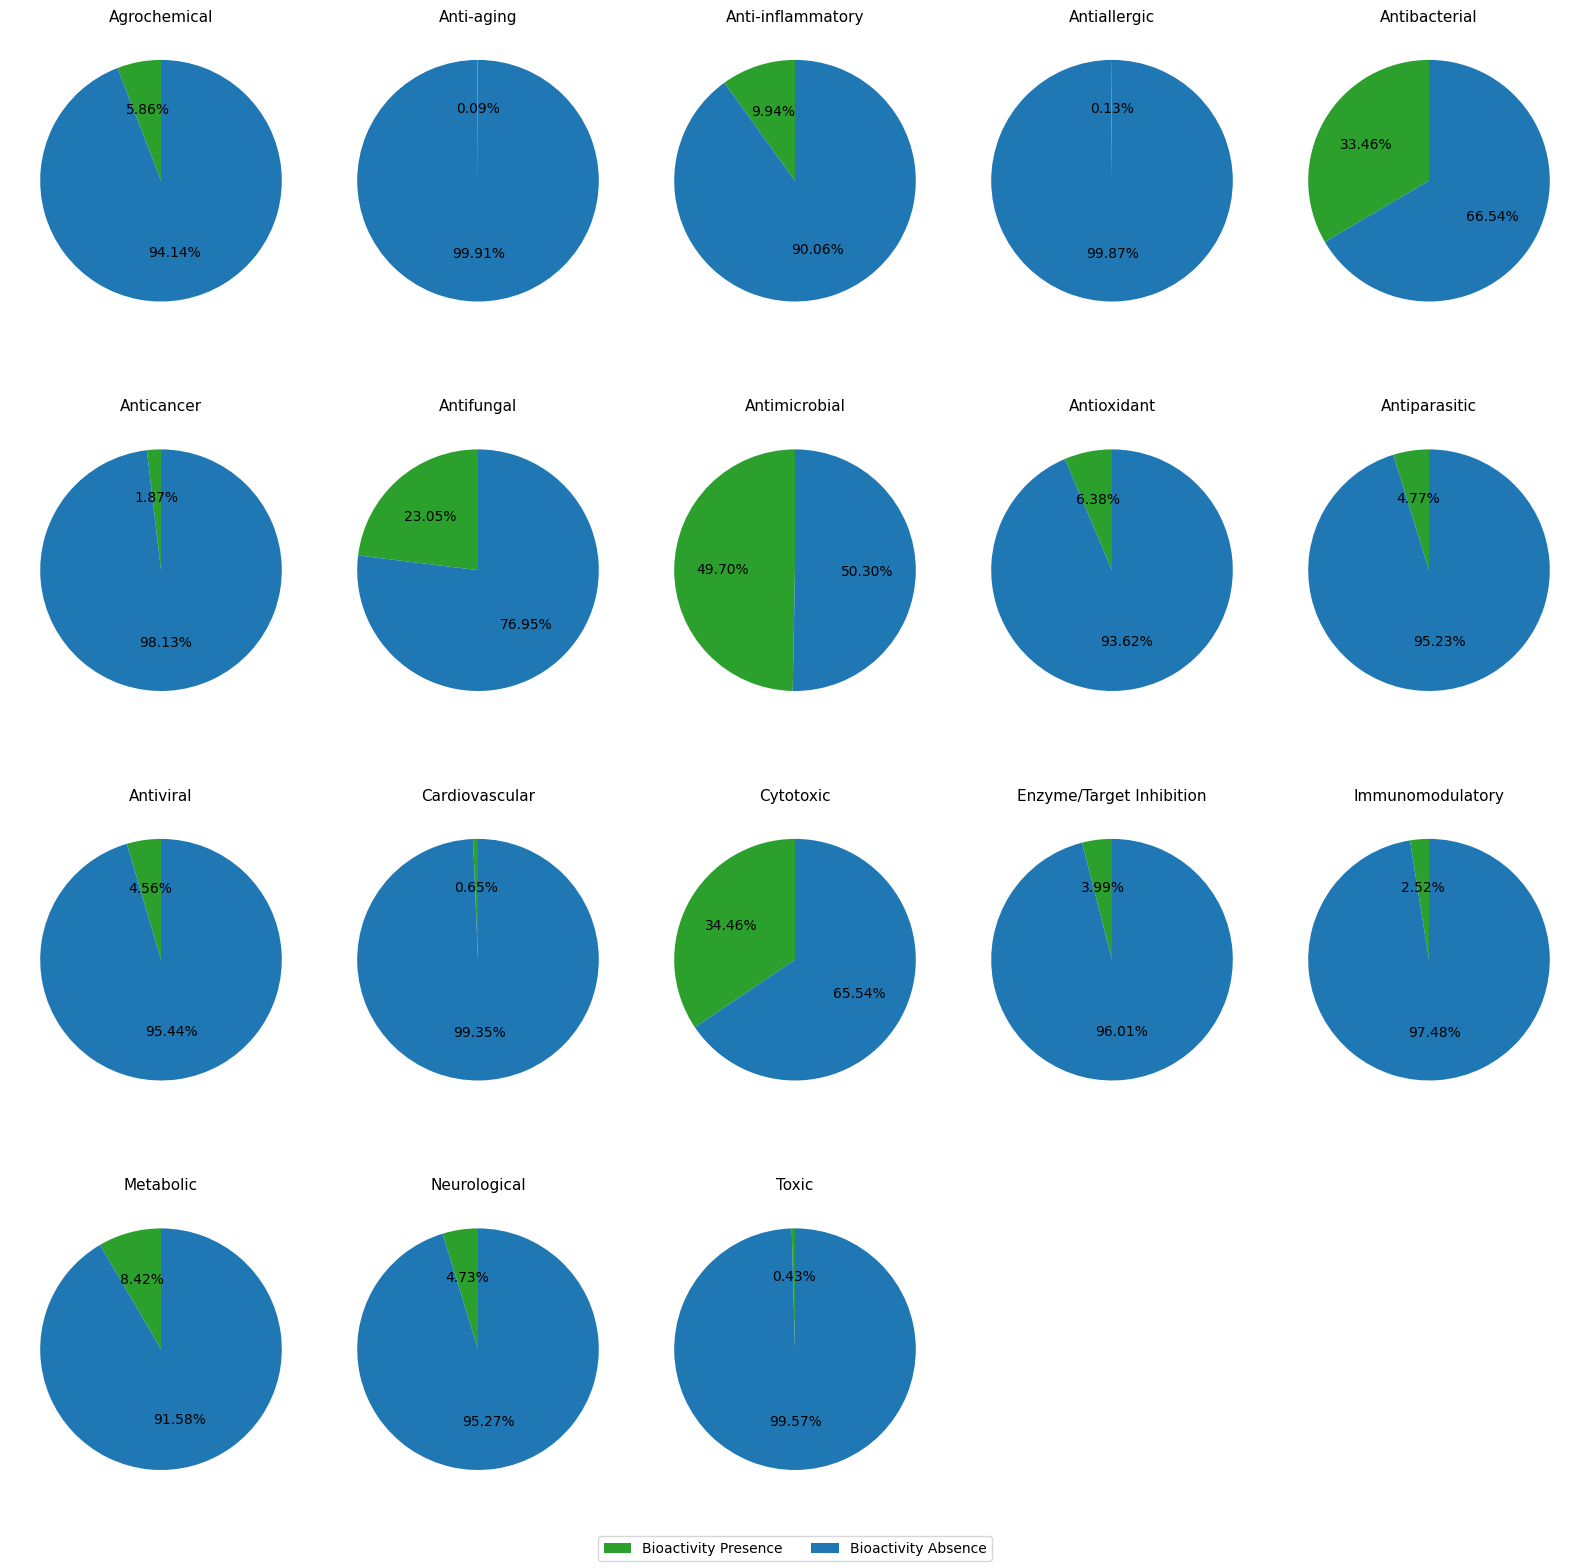

In [28]:
from matplotlib.patches import Patch
# Plot imbalance bioactivties
n = len(multilabel_data_df)

ncols = 5
nrows = math.ceil(len(Bio_cols)/ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(16, 4*nrows))
axes = axes.flatten()

colors = ["tab:green", "tab:blue"]

for ax, col in zip(axes, Bio_cols):

  present = multilabel_data_df[col].sum()
  absent = n - present

  ax.pie([present, absent], autopct='%1.2f%%', colors=colors, startangle=90)
  ax.set_title(col, fontsize=11)

  # remove empty subplots
  for ax in axes[len(Bio_cols):]:
    ax.axis("off")

legend_elements = [
    Patch(facecolor="tab:green", label="Bioactivity Presence"),
    Patch(facecolor="tab:blue", label="Bioactivity Absence")
]

fig.legend(handles=legend_elements, loc="lower center", ncol=2)

plt.tight_layout()
plt.savefig("Bioactivity_imbalance_fig.png", dpi=300, bbox_inches="tight")
plt.savefig("Bioactivity_imbalance_fig.pdf", bbox_inches='tight',pad_inches=0.05)
plt.show()

In [29]:
df_marged = meta_data_df.merge(multilabel_data_df, on="compound_id", how="inner")

In [30]:
# Counts per class × bioactivity (sum of 0/1)
df_marged[Bio_cols] = df_marged[Bio_cols].fillna(0).astype(int)
counts = df_marged.groupby("NP_pathway")[Bio_cols].sum().astype(int)

#  % per class (row-normalized)
totals = df_marged.groupby("NP_pathway").size()
perc = (counts.div(totals, axis=0) * 100).round(2)

# Save tables (optional)
counts.to_csv("class_by_bio_counts.csv")
perc.to_csv("class_by_bio_percent.csv")

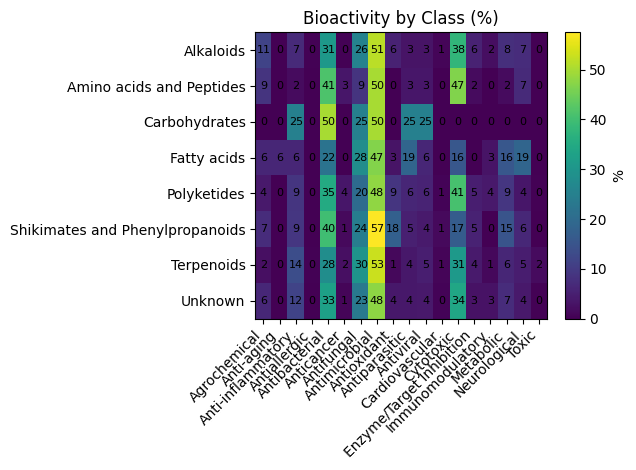

In [31]:
# Heatmap of % with annotations (pure matplotlib)
fig, ax = plt.subplots()
im = ax.imshow(perc.values, aspect="auto")
ax.set_xticks(range(len(Bio_cols))); ax.set_xticklabels(Bio_cols, rotation=45, ha="right")
ax.set_yticks(range(len(perc.index))); ax.set_yticklabels(perc.index)
ax.set_title("Bioactivity by Class (%)")
fig.colorbar(im, ax=ax, label="%")
# annotate cells
for i in range(perc.shape[0]):
    for j in range(perc.shape[1]):
        ax.text(j, i, f"{perc.values[i, j]:.0f}", ha="center", va="center", fontsize=8)
plt.tight_layout()
plt.savefig("class_by_bio_fig.png", dpi=300, bbox_inches="tight")
plt.savefig("class_by_bio_fig.pdf", bbox_inches='tight',pad_inches=0.05)
plt.show()

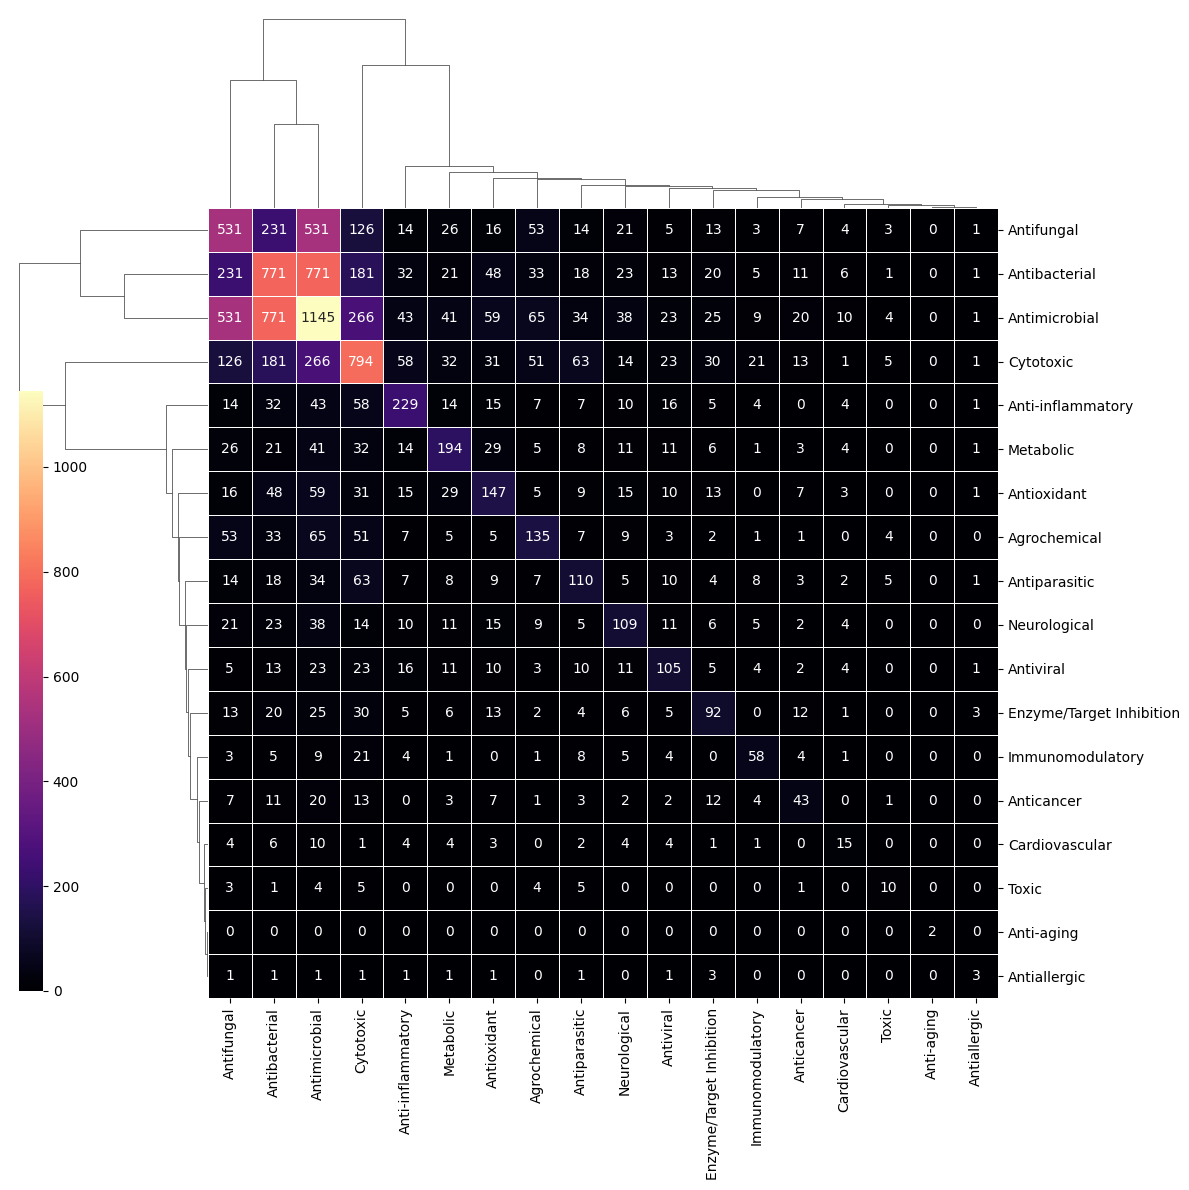

In [32]:
import seaborn as sns

labels_df = multilabel_data_df[Bio_cols]

# Compute co-occurrence matrix
co_occurrence = labels_df.T.dot(labels_df)

# Draw clustered heatmap
g = sns.clustermap(
    co_occurrence,
    cmap="magma",
    annot=True,
    fmt="d",
    figsize=(12, 12),
    linewidths=0.5,
    cbar_pos=(0.02, 0.17, 0.02, 0.5)
)

# Clean labels
g.ax_heatmap.set_xlabel("")
g.ax_heatmap.set_ylabel("")


plt.savefig(
    "bioactivity_cooccurrence_heatmap.png", dpi=600, bbox_inches="tight")
plt.savefig("bioactivity_cooccurrence_heatmap.pdf", bbox_inches='tight',
            pad_inches=0.05)
plt.show()

In [36]:
# save the dataset
meta_data_df.to_csv("final_compound_metadata.csv",index=False)

In [33]:
!pip install venn matplotlib

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for venn: filename=venn-0.1.3-py3-none-any.whl size=19782 sha256=bb855877f98224ad62ef1b9aaa55e24f4b47532a91a08c7e3255d68148e31cdf
  Stored in directory: /root/.cache/pip/wheels/4b/ef/db/388ec89f2cea595e9130857edcc7a90f2fc5db5b2cbc59ce11
Successfully built venn


<Figure size 600x600 with 0 Axes>

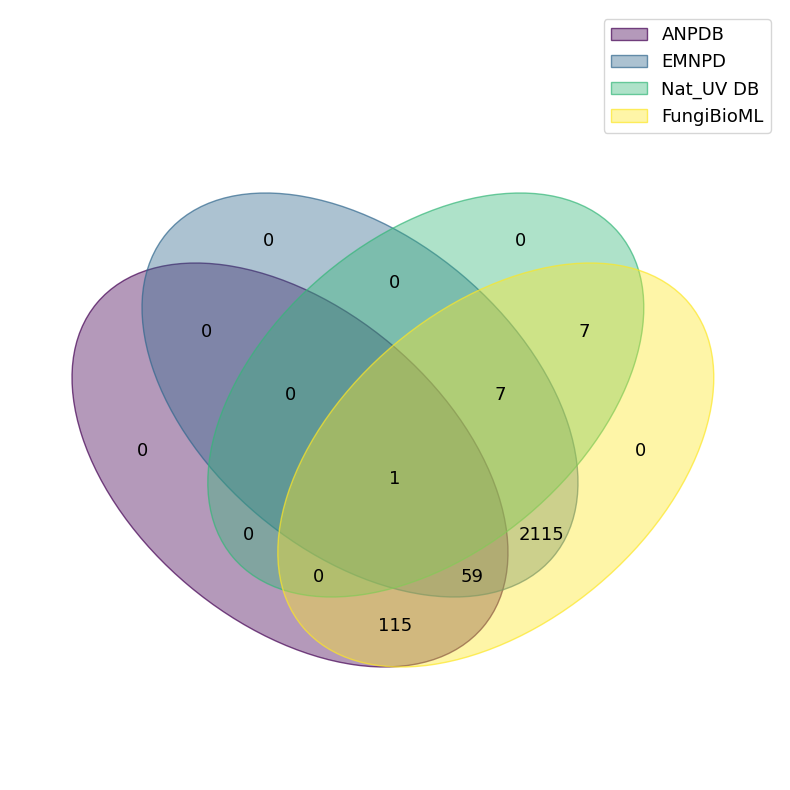

In [37]:
from venn import venn
df_a = pd.read_csv("ANPDB_processed.csv")
df_b = pd.read_csv("EMNPD_processed.csv")
df_c = pd.read_csv("nat_uv_db_processed.csv")
df_d = pd.read_csv("final_compound_metadata.csv")
id_col = "InChIKey"
set_a = set(df_a[id_col].dropna())
set_b = set(df_b[id_col].dropna())
set_c = set(df_c[id_col].dropna())
set_d = set(df_d[id_col].dropna())
datasets = {"ANPDB": set_a ,"EMNPD": set_b,"Nat_UV DB": set_c,"FungiBioML": set_d}

plt.figure(figsize=(6, 6))

venn(datasets)

#plt.title("Overlap of compounds across source databases")

plt.tight_layout()

plt.savefig("source_database_overlap.png", dpi=600, bbox_inches="tight")
plt.savefig("source_database_overlap.pdf", bbox_inches="tight")

plt.show()